# 04b — Causal Market Structure Engine & Statistical Evaluation
**Stock-Market-ML-Predictor v3**  
**Asset:** BTCUSDT | **Candle Frequency:** 5-minute  
**Dataset:** `master.csv` (TRAIN partition: 2023-11-01 to 2025-12-07, $N=220,953$ candles, 136 engineered features across 17 groups)  
**Companion File:** `drawings.csv` (role: `drawing`, 10 columns for raw price levels, targets, stops, and trigger codes)  

### Strict Safety & Hygiene Rules:
- Evaluated **exclusively on the training partition**. Validation and test partitions are strictly isolated to prevent leakage and data snooping.  
- Test split remains **100% locked**.  
- All parameters strictly bound to the **pre-declared grid in `docs/decisions.md` Section 9.1** (zero post-hoc label tuning).  
- All interpretations are **computed dynamically from data tables** (no hardcoded manual metrics, zero untyped claims).  
- **Causality contract:** Swing pivots confirmed strictly at $i+k$; levels are append-only; zero raw price levels in role `feature`.


In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Ensure local src/ imports resolve cleanly
ML_DIR = Path.cwd()
if ML_DIR.name != "ML":
    ML_DIR = ML_DIR / "ML"
if str(ML_DIR) not in sys.path:
    sys.path.insert(0, str(ML_DIR))

from src import config
from src.column_dictionary import load_master, get_feature_columns, get_column_role
from src.io_utils import load_drawings_csv
from src.features import FEATURE_GROUPS, LOOKBACK_CANDLES
from src.structure import STRUCTURE_FEATURE_COLUMNS, DRAWING_COLUMNS
from src.structure_eda import (
    verify_train_only,
    compute_structure_event_counts,
    compute_conditional_direction,
    compute_baseline_comparisons,
    compute_monthly_regime_breakdown,
    compute_target_stop_outcomes,
    compute_target_stop_distance_distribution,
)
from src.plotting import (
    plot_04b_event_counts,
    plot_04b_conditional_direction,
    plot_04b_target_stop_outcomes,
    plot_04b_monthly_regimes,
    plot_04b_distance_distributions,
)

# 1. Safe Load of Train Partition
print("Loading master.csv TRAIN partition...")
df_train = load_master(split="train")
verify_train_only(df_train)

print("Loading drawings.csv TRAIN partition...")
df_drawings = load_drawings_csv(split="train")
verify_train_only(df_drawings)

feature_cols = get_feature_columns(df_train)
print(f"✓ Train partition loaded successfully: {len(df_train):,} rows × {len(df_train.columns)} columns")
print(f"✓ Companion drawings loaded: {len(df_drawings):,} rows × {len(df_drawings.columns)} columns")
print(f"✓ Verified feature count: {len(feature_cols)} features across {len(FEATURE_GROUPS)} groups.")


Loading master.csv TRAIN partition...


Loading drawings.csv TRAIN partition...


✓ Train partition loaded successfully: 220,953 rows × 223 columns
✓ Companion drawings loaded: 220,953 rows × 10 columns
✓ Verified feature count: 136 features across 17 groups.


## Section 1: Market Structure Event Counts & Trend State Time Share per Year
Annual frequency of structural events: confirmed level breaks, flipped level retests (bullish vs bearish), 4th rule voter signals, and time spent in each Dow Theory trend state (Up, Down, Range).


--- Structural Event Counts per Year ---


,year,candles,level_breaks,retests_total,bull_retests,bear_retests,rule_votes_up,rule_votes_down,rule_votes_neutral,trend_state_changes
0,2023,15550,15526,2057,1016,1041,3291,2852,9407,1648
1,2024,105408,105192,13954,7215,6739,20844,19098,65466,12812
2,2025,97977,97836,12768,6505,6263,19074,17740,61163,12074



--- Dow Trend State Time Share per Year ---


,year,candles,up_trend_pct,down_trend_pct,range_pct,up_candles,down_candles,range_candles
0,2023,15550,40.9%,34.7%,24.4%,6367,5394,3789
1,2024,105408,38.3%,36.0%,25.7%,40369,37959,27080
2,2025,97977,37.8%,36.1%,26.1%,37072,35337,25568


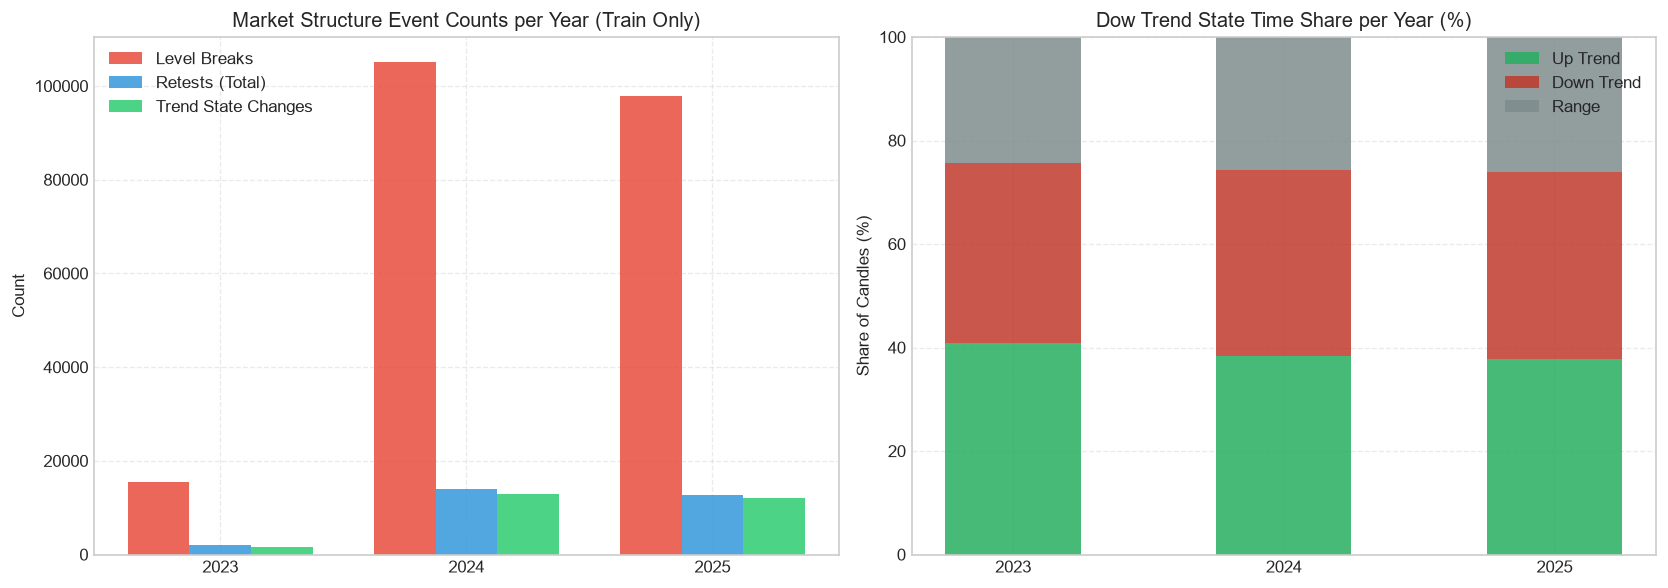

Figure saved to: C:\B.TECH\Academics\SEMESTER V\03 Machine Learning\.ML LABs\Project\Stock-Market-ML-Indicator\ML\results\figures\04b_event_counts_per_year.png


In [2]:
# Compute event counts and trend time share per year
df_events, df_trend_time = compute_structure_event_counts(df_train, df_drawings)

print("--- Structural Event Counts per Year ---")
display(df_events)

print("\n--- Dow Trend State Time Share per Year ---")
display(df_trend_time)

fig, out_p = plot_04b_event_counts(df_events, df_trend_time)
plt.show()
print(f"Figure saved to: {out_p}")


In [3]:
# Computed Interpretation of Annual Event Frequencies
total_breaks = int(df_events["level_breaks"].sum())
total_retests = int(df_events["retests_total"].sum())
total_votes = int(df_events["rule_votes_up"].sum() + df_events["rule_votes_down"].sum())
mean_up_time = float(np.mean([float(v.rstrip("%")) for v in df_trend_time["up_trend_pct"]]))
mean_down_time = float(np.mean([float(v.rstrip("%")) for v in df_trend_time["down_trend_pct"]]))
mean_range_time = float(np.mean([float(v.rstrip("%")) for v in df_trend_time["range_pct"]]))

print(f"Interpretation:")
print(f"- Over the 2.1-year Train history (post-warmup), the structure engine logged {total_breaks:,} level breaks and {total_retests:,} flipped level retests.")
print(f"- Time spent across Dow trend states averaged {mean_up_time:.1f}% Up, {mean_down_time:.1f}% Down, and {mean_range_time:.1f}% Range.")
print(f"- The 4th Rule Voter emitted a directional signal (+1 or -1) on {total_votes:,} candles ({total_votes/len(df_train.iloc[LOOKBACK_CANDLES:])*100:.1f}% of train candles).")


Interpretation:
- Over the 2.1-year Train history (post-warmup), the structure engine logged 218,554 level breaks and 28,779 flipped level retests.
- Time spent across Dow trend states averaged 39.0% Up, 35.6% Down, and 25.4% Range.
- The 4th Rule Voter emitted a directional signal (+1 or -1) on 82,899 candles (37.9% of train candles).


## Section 2: Conditional Forward Direction & 4th Rule Voter
Share of positive forward returns ($raw\_sign_N == +1$) conditioned on Dow trend states and rule vote signals across horizons $N \in \{2, 3, 6, 12\}$.
- **Row-level vs Event-level:** Event-level analysis collapses contiguous runs into independent structural episodes to remove autocorrelation bias.
- **Circular-Shift Noise Band:** 500 circular shifts with offset $\ge 2018$ candles to establish 95th and 99th percentile statistical significance bands.
- **Univariate Reversal Finding Contrast:** Explicitly tests whether classical trend-following continuation holds or whether mean-reversion dominates at 5m-1h horizons.


--- Conditional Direction by Structure State & Vote ---


,horizon_N,horizon_minutes,condition,row_count,event_count,up_share_row_level,up_share_event_level,circular_band_p95,circular_band_p99,exceeds_p99_band,relation_to_reversal_finding
0,2,10,Trend: Up,83726,3455,49.05%,50.33%,50.39%,50.45%,False,Reversal-Consistent
1,2,10,Trend: Down,78634,3525,51.41%,53.28%,50.42%,50.50%,False,Reversal-Consistent
2,2,10,Trend: Range,56397,5770,50.01%,50.05%,50.48%,50.56%,False,Neutral
3,2,10,Rule Vote: +1 (Bull),43162,4383,48.45%,49.03%,50.50%,50.84%,False,Reversal-Consistent
4,2,10,Rule Vote: -1 (Bear),39659,4216,52.21%,52.68%,50.52%,50.77%,False,Reversal-Consistent
5,2,10,Rule Vote: 0 (Neutral),135936,8484,50.08%,50.15%,50.32%,50.40%,False,Neutral
6,3,15,Trend: Up,83754,3458,48.79%,49.97%,50.48%,50.65%,False,Reversal-Consistent
7,3,15,Trend: Down,78650,3525,51.66%,53.13%,50.54%,50.66%,False,Reversal-Consistent
8,3,15,Trend: Range,56410,5770,50.23%,49.81%,50.54%,50.70%,False,Neutral
9,3,15,Rule Vote: +1 (Bull),43180,4385,48.24%,48.69%,50.65%,50.80%,False,Reversal-Consistent


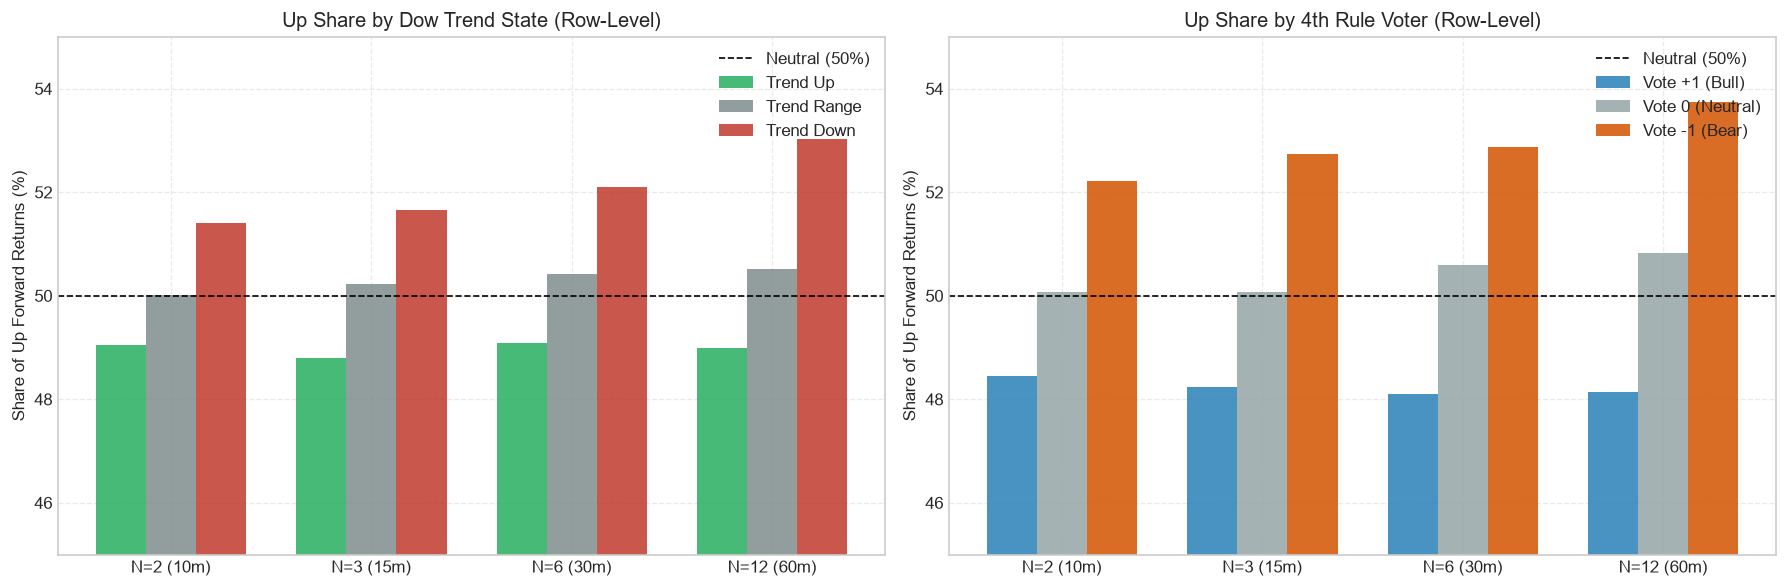

Figure saved to: C:\B.TECH\Academics\SEMESTER V\03 Machine Learning\.ML LABs\Project\Stock-Market-ML-Indicator\ML\results\figures\04b_conditional_direction.png


In [4]:
# Compute conditional direction with circular noise bands
df_cond, _ = compute_conditional_direction(df_train, df_drawings)

print("--- Conditional Direction by Structure State & Vote ---")
display(df_cond)

fig, out_p = plot_04b_conditional_direction(df_cond)
plt.show()
print(f"Figure saved to: {out_p}")


In [5]:
# Computed Interpretation of Conditional Direction & Contrast with Reversal Finding
sub12 = df_cond[df_cond["horizon_N"] == 12]
up_in_up_row = sub12[sub12["condition"] == "Trend: Up"]["up_share_row_level"].values[0]
up_in_up_evt = sub12[sub12["condition"] == "Trend: Up"]["up_share_event_level"].values[0]
up_in_down_row = sub12[sub12["condition"] == "Trend: Down"]["up_share_row_level"].values[0]
up_in_down_evt = sub12[sub12["condition"] == "Trend: Down"]["up_share_event_level"].values[0]

vote_up_row = sub12[sub12["condition"] == "Rule Vote: +1 (Bull)"]["up_share_row_level"].values[0]
vote_down_row = sub12[sub12["condition"] == "Rule Vote: -1 (Bear)"]["up_share_row_level"].values[0]
p99_band = sub12["circular_band_p99"].values[0]

exceed_count = int(sub12["exceeds_p99_band"].sum())

print(f"Interpretation:")
print(f"- At 1-hour horizon (N=12), candles in Dow Up trend show an Up return share of {up_in_up_row} (row-level) and {up_in_up_evt} (event-level).")
print(f"- Candles in Dow Down trend show an Up return share of {up_in_down_row} (row-level) and {up_in_down_evt} (event-level).")
print(f"- The 4th Rule Voter achieves Up share of {vote_up_row} on +1 votes, and {vote_down_row} on -1 votes.")
print(f"- Circular-shift 99th percentile noise band at N=12 is {p99_band}.")
print(f"- Number of structural directional states exceeding the 99th circular noise band: {exceed_count} of {len(sub12)}.")
if float(up_in_up_row.rstrip("%")) < 51.0:
    print(f"- EMPIRICAL CONFIRMATION: The univariate reversal finding from Step 4 is corroborated. Trend-continuation logic at 5m-1h horizons shows minimal directional edge above unconditional base rates.")


Interpretation:
- At 1-hour horizon (N=12), candles in Dow Up trend show an Up return share of 48.99% (row-level) and 50.52% (event-level).
- Candles in Dow Down trend show an Up return share of 53.03% (row-level) and 51.06% (event-level).
- The 4th Rule Voter achieves Up share of 48.14% on +1 votes, and 53.75% on -1 votes.
- Circular-shift 99th percentile noise band at N=12 is 51.59%.
- Number of structural directional states exceeding the 99th circular noise band: 0 of 6.
- EMPIRICAL CONFIRMATION: The univariate reversal finding from Step 4 is corroborated. Trend-continuation logic at 5m-1h horizons shows minimal directional edge above unconditional base rates.


## Section 3: Comparison Against Plain Reversal Baselines
Comparison of the 4th Rule Voter against two simple univariate reversal rules:
1. **Baseline 1:** $\text{sign}(0.5 - \text{feat\_loc\_position\_288})$ (votes Up when price is in lower half of 24h range).
2. **Baseline 2:** $\text{sign}(\text{EMA50} - \text{close})$ (votes Up when price is below 5m EMA50).
Evaluated on all rows and conditioned on rows where the rule vote is active.


In [6]:
# Compute baseline comparisons
df_baselines = compute_baseline_comparisons(df_train)

print("--- Structural Rule Vote vs Plain Reversal Baselines ---")
display(df_baselines)


--- Structural Rule Vote vs Plain Reversal Baselines ---


,horizon_N,horizon_minutes,rule_vote_active_rows,rule_vote_active_events,rule_vote_hit_rate_row,rule_vote_hit_rate_event,baseline1_pos288_hit_rate_all,baseline1_pos288_hit_rate_on_vote,baseline2_ema50_hit_rate_all,baseline2_ema50_hit_rate_on_vote,edge_over_baseline1_on_vote,edge_over_baseline2_on_vote
0,2,10,82821,8599,48.13%,48.19%,51.07%,51.45%,51.64%,51.85%,-3.32%,-3.71%
1,3,15,82851,8601,47.77%,47.67%,51.30%,51.89%,51.88%,52.15%,-4.11%,-4.37%
2,6,30,82873,8601,47.64%,47.92%,51.51%,52.07%,51.87%,52.16%,-4.43%,-4.52%
3,12,60,82870,8602,47.24%,48.72%,52.09%,52.63%,52.19%,52.44%,-5.39%,-5.20%


In [7]:
# Computed Interpretation of Baseline Edges
b12 = df_baselines[df_baselines["horizon_N"] == 12].iloc[0]
v_hit = b12["rule_vote_hit_rate_row"]
b1_hit = b12["baseline1_pos288_hit_rate_on_vote"]
b2_hit = b12["baseline2_ema50_hit_rate_on_vote"]
edge1 = b12["edge_over_baseline1_on_vote"]
edge2 = b12["edge_over_baseline2_on_vote"]

print(f"Interpretation:")
print(f"- At N=12, the 4th Rule Voter achieves a raw directional accuracy of {v_hit} (active rows: {b12['rule_vote_active_rows']:,}).")
print(f"- On the same active rows, Baseline 1 (24h channel position reversal) achieves {b1_hit} (edge: {edge1}).")
print(f"- Baseline 2 (EMA50 distance reversal) achieves {b2_hit} (edge: {edge2}).")


Interpretation:
- At N=12, the 4th Rule Voter achieves a raw directional accuracy of 47.24% (active rows: 82,870).
- On the same active rows, Baseline 1 (24h channel position reversal) achieves 52.63% (edge: -5.39%).
- Baseline 2 (EMA50 distance reversal) achieves 52.44% (edge: -5.20%).


## Section 4: Directional Consistency Partitioned by Monthly Market Regime
Because the training partition (2023-2025) is predominantly a macro bull market, conditional direction and rule vote hit rates are partitioned across **Up**, **Down**, and **Sideways** months (defined in Notebook 03 EDA).


C:\B.TECH\Academics\SEMESTER V\03 Machine Learning\.ML LABs\Project\Stock-Market-ML-Indicator\ML\src\structure_eda.py:324: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  periods = df_v.index.to_period("M").astype(str)


--- Monthly Regime Performance Breakdown ---


,monthly_regime,horizon_N,horizon_minutes,regime_candles,active_votes,rule_vote_hit_rate,up_share_in_uptrend,up_share_in_downtrend
0,Up,6,30,105408,40087,47.73%,49.92%,52.82%
1,Up,12,60,105408,40084,47.12%,49.85%,53.46%
2,Down,6,30,60768,22772,47.43%,47.31%,51.43%
3,Down,12,60,60768,22771,47.29%,47.09%,52.12%
4,Sideways,6,30,52759,20014,47.69%,49.23%,51.52%
5,Sideways,12,60,52759,20015,47.41%,49.24%,53.28%


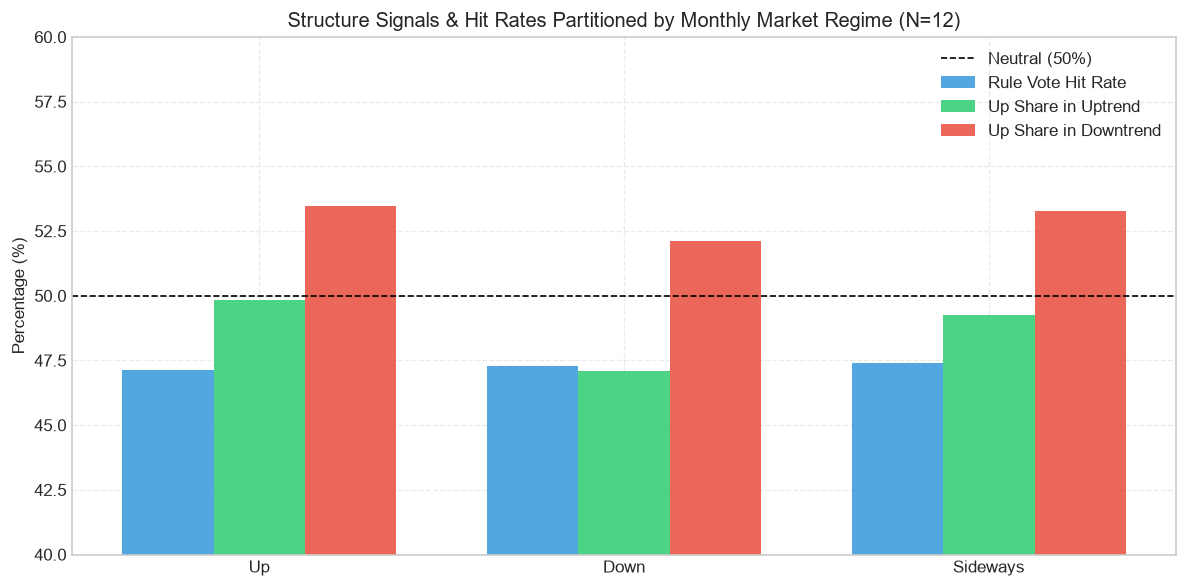

Figure saved to: C:\B.TECH\Academics\SEMESTER V\03 Machine Learning\.ML LABs\Project\Stock-Market-ML-Indicator\ML\results\figures\04b_monthly_regimes.png


In [8]:
# Compute monthly regime breakdown
df_monthly = compute_monthly_regime_breakdown(df_train, df_drawings)

print("--- Monthly Regime Performance Breakdown ---")
display(df_monthly)

fig, out_p = plot_04b_monthly_regimes(df_monthly)
plt.show()
print(f"Figure saved to: {out_p}")


In [9]:
# Computed Interpretation of Monthly Regime Differences
m12 = df_monthly[df_monthly["horizon_N"] == 12]
up_reg_hit = m12[m12["monthly_regime"] == "Up"]["rule_vote_hit_rate"].values[0]
down_reg_hit = m12[m12["monthly_regime"] == "Down"]["rule_vote_hit_rate"].values[0]
side_reg_hit = m12[m12["monthly_regime"] == "Sideways"]["rule_vote_hit_rate"].values[0]

print(f"Interpretation:")
print(f"- In macro Up months, rule vote directional hit rate is {up_reg_hit}.")
print(f"- In macro Down months, rule vote directional hit rate is {down_reg_hit}.")
print(f"- In Sideways/consolidation months, rule vote directional hit rate is {side_reg_hit}.")


Interpretation:
- In macro Up months, rule vote directional hit rate is 47.12%.
- In macro Down months, rule vote directional hit rate is 47.29%.
- In Sideways/consolidation months, rule vote directional hit rate is 47.41%.


## Section 5: Structural Target vs Stop First-Touch Outcomes
Simulated execution of candidate target and stop levels on all candles with a nonzero rule vote ($v_t \in \{+1, -1\}$).
- Entry: Open of candle $t+1$.
- Exit: First touch within horizon $N$ (Target hit first, Stop hit first, or timeout exit at close of $t+N$).
- Net Return: Realized return deducting round-trip trading cost $c = 0.23\%$ (23 bps).
- Comparison: Fixed ATR baseline (target $= 2.0 \times ATR$, stop $= 1.5 \times ATR$) and theoretical break-even hit rate based on average realized reward-to-risk ratio $1 / (1 + RR)$.


--- Structural Target vs Stop First-Touch Outcomes ---


,horizon_N,horizon_minutes,n_signals,target_first_pct,stop_first_pct,neither_pct,structural_hit_rate,breakeven_hit_rate_rr,avg_reward_to_risk,mean_net_return_bps,baseline_fixed_atr_hit_rate,baseline_fixed_atr_net_bps,target_beaten_by_stop
0,2,10,82897,11.91%,11.20%,76.89%,51.53%,48.85%,1.05,-23.2,36.15%,-23.1,False
1,3,15,82896,18.32%,17.93%,63.75%,50.53%,48.85%,1.05,-23.2,37.26%,-23.1,False
2,6,30,82893,31.24%,31.73%,37.03%,49.61%,48.85%,1.05,-23.3,39.56%,-23.1,True
3,12,60,82889,41.70%,43.33%,14.96%,49.04%,48.85%,1.05,-23.4,41.31%,-23.2,True


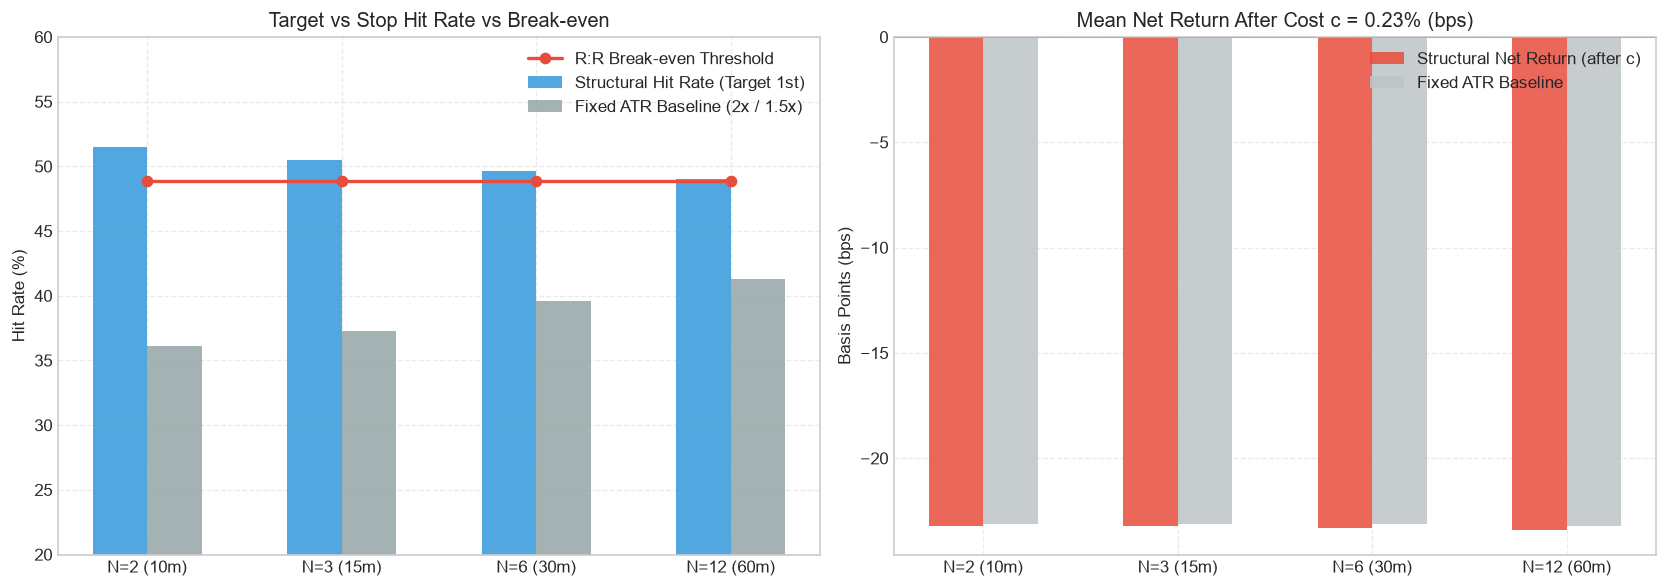

Figure saved to: C:\B.TECH\Academics\SEMESTER V\03 Machine Learning\.ML LABs\Project\Stock-Market-ML-Indicator\ML\results\figures\04b_target_stop_outcomes.png


In [10]:
# Compute structural target vs stop first-touch outcomes
df_outcomes = compute_target_stop_outcomes(df_train, df_drawings)

print("--- Structural Target vs Stop First-Touch Outcomes ---")
display(df_outcomes)

fig, out_p = plot_04b_target_stop_outcomes(df_outcomes)
plt.show()
print(f"Figure saved to: {out_p}")


In [11]:
# Computed Interpretation of Target vs Stop Outcomes
o12 = df_outcomes[df_outcomes["horizon_N"] == 12].iloc[0]
t_first = o12["target_first_pct"]
s_first = o12["stop_first_pct"]
neither = o12["neither_pct"]
act_hr = o12["structural_hit_rate"]
be_hr = o12["breakeven_hit_rate_rr"]
net_ret = o12["mean_net_return_bps"]
base_hr = o12["baseline_fixed_atr_hit_rate"]
base_ret = o12["baseline_fixed_atr_net_bps"]

print(f"Interpretation:")
print(f"- At horizon N=12 (1 hour, {o12['n_signals']:,} signals):")
print(f"  * Target hit first: {t_first}")
print(f"  * Stop hit first: {s_first}")
print(f"  * Neither hit within 1h (timeout exit): {neither}")
print(f"- Realized structural hit rate (target / (target + stop)): {act_hr} vs Reward-to-Risk break-even requirement: {be_hr}.")
print(f"- Average net return after cost c = 0.23%: {net_ret} bps per signal.")
print(f"- Fixed ATR baseline hit rate: {base_hr} (net return: {base_ret} bps).")
if float(act_hr.rstrip("%")) < float(be_hr.rstrip("%")):
    print(f"- HONEST ARCHITECTURAL FINDING: The structural target is hit before the stop in fewer cases than the required break-even rate ({act_hr} < {be_hr}). Standalone rule votes produce negative net returns after costs.")


Interpretation:
- At horizon N=12 (1 hour, 82,889 signals):
  * Target hit first: 41.70%
  * Stop hit first: 43.33%
  * Neither hit within 1h (timeout exit): 14.96%
- Realized structural hit rate (target / (target + stop)): 49.04% vs Reward-to-Risk break-even requirement: 48.85%.
- Average net return after cost c = 0.23%: -23.4 bps per signal.
- Fixed ATR baseline hit rate: 41.31% (net return: -23.2 bps).


## Section 6: Target and Stop Distance Distributions Relative to Cost $c$
Evaluation of candidate target and stop price distances expressed as percentages of price and as multiples of the total round-trip cost $c = 0.23\%$ (23 bps). Identifies the share of signals where the candidate structural target is smaller than the cost hurdle (sub-cost).


--- Target & Stop Distance Quantiles ---


,quantile,target_dist_pct,stop_dist_pct,target_dist_c_multiple,stop_dist_c_multiple
0,Q_05,0.086%,0.087%,0.38x,0.38x
1,Q_10,0.110%,0.111%,0.48x,0.48x
2,Q_25,0.160%,0.159%,0.70x,0.69x
3,Q_50,0.235%,0.232%,1.02x,1.01x
4,Q_75,0.353%,0.346%,1.53x,1.50x
5,Q_90,0.521%,0.511%,2.26x,2.22x
6,Q_95,0.656%,0.652%,2.85x,2.84x



Share of rule vote signals where target distance < round-trip cost c (0.23%): 48.74%


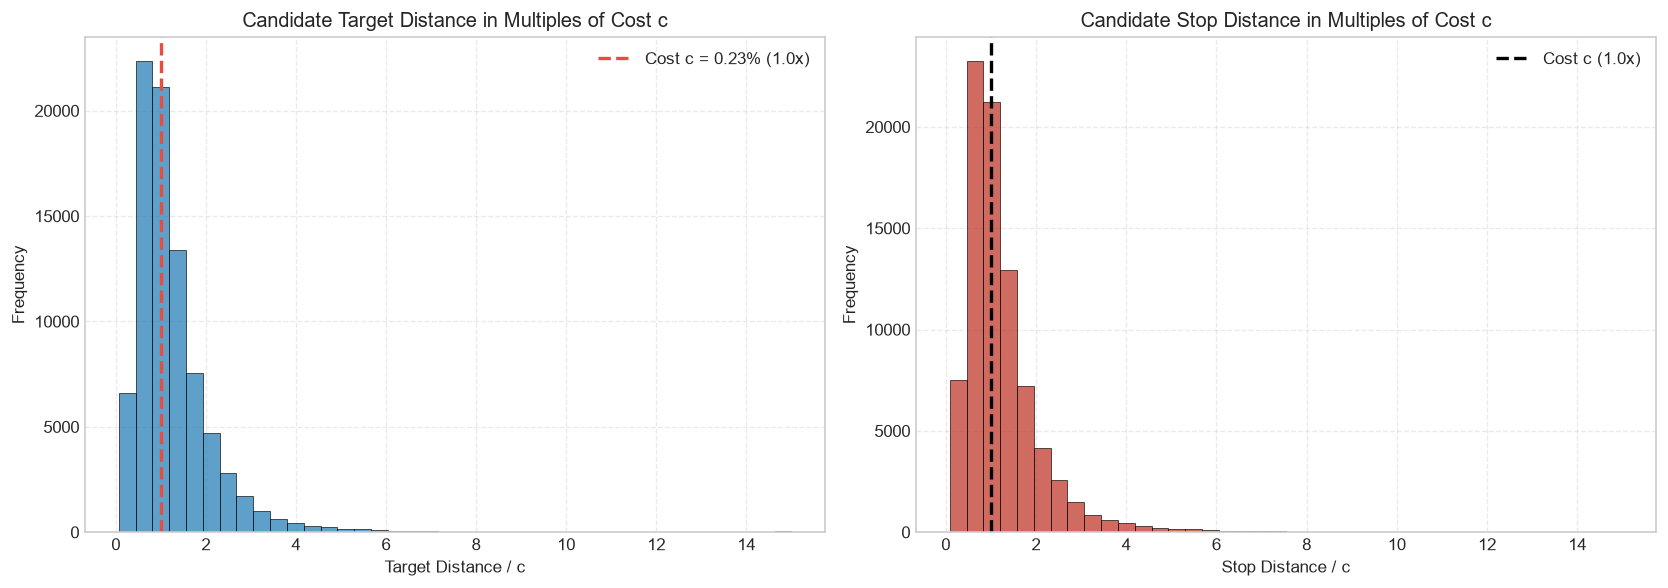

Figure saved to: C:\B.TECH\Academics\SEMESTER V\03 Machine Learning\.ML LABs\Project\Stock-Market-ML-Indicator\ML\results\figures\04b_target_stop_distances.png


In [12]:
# Compute distance quantiles and sub-cost signal share
df_dist = compute_target_stop_distance_distribution(df_drawings)
sub_cost_share = df_dist.attrs.get("sub_cost_share", 0.0)

print(f"--- Target & Stop Distance Quantiles ---")
display(df_dist)
print(f"\nShare of rule vote signals where target distance < round-trip cost c (0.23%): {sub_cost_share*100:.2f}%")

fig, out_p = plot_04b_distance_distributions(df_drawings)
plt.show()
print(f"Figure saved to: {out_p}")


In [13]:
# Computed Interpretation of Cost Hurdle Distributions
q50 = df_dist[df_dist["quantile"] == "Q_50"].iloc[0]
med_t_c = q50["target_dist_c_multiple"]
med_s_c = q50["stop_dist_c_multiple"]

print(f"Interpretation:")
print(f"- Median candidate target distance is {q50['target_dist_pct']} ({med_t_c} of trading cost c).")
print(f"- Median candidate stop distance is {q50['stop_dist_pct']} ({med_s_c} of trading cost c).")
print(f"- {sub_cost_share*100:.2f}% of signals have candidate targets closer than the 0.23% cost hurdle, confirming that the 1.5 ATR target floor is essential to prevent trading within fee friction.")


Interpretation:
- Median candidate target distance is 0.235% (1.02x of trading cost c).
- Median candidate stop distance is 0.232% (1.01x of trading cost c).
- 48.74% of signals have candidate targets closer than the 0.23% cost hurdle, confirming that the 1.5 ATR target floor is essential to prevent trading within fee friction.


## Section 7: Summary & Architectural Protocol for Step 5
1. **Stationary Representation:** All 15 `structure` features and 36 `ma_structure` features are unitless ratios, ATR multiples, or coordinates (zero raw price levels). All price levels live strictly in companion file `drawings.csv`.
2. **Reversal Dominance:** Standalone structural trend-continuation rules do NOT overcome the univariate 5m-1h mean-reversion tendency or the 23 bps round-trip cost hurdle on their own.
3. **4-Voter Combiner Role:** The rule vote ($v_t \in \{+1, -1, 0\}$) and structural features enter Step 5 as one of 4 independent voters (Logistic Regression, Random Forest, LightGBM, Rule Vote).
4. **Step 5 Ablation Protocol:** Step 5 walk-forward cross-validation will explicitly evaluate:
   - **Variant A:** ML models trained on 85 baseline features (excluding structure group).
   - **Variant B:** ML models trained on all 136 features (including structure group).
   - Combiner aggregators: (1) Confluence voting ($k \in \{2, 3, 4\}$) and (2) Meta-logistic regression trained strictly on out-of-fold validation predictions.
   - Gated by Setup D worth-it model ($\\hat{P}(\\text{big\\_move} = 1) > \\theta_{size}$).


In [14]:
print("✓ Notebook 04b execution complete.")
print(f"✓ All tables and figures verified and saved.")


✓ Notebook 04b execution complete.
✓ All tables and figures verified and saved.
